**Load the Dependencies**

In [ ]:
# Dependencies
import kagglehub
from kagglehub import KaggleDatasetAdapter
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Load the Data**

In [ ]:
file = "fake_job_postings.csv"

hf_dataset = kagglehub.load_dataset(
  KaggleDatasetAdapter.HUGGING_FACE,
  "shivamb/real-or-fake-fake-jobposting-prediction", file)

/tmp/ipykernel_6578/314233240.py:3: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  hf_dataset = kagglehub.load_dataset(


Using Colab cache for faster access to the 'real-or-fake-fake-jobposting-prediction' dataset.


**Explore the data**

In [ ]:
print(hf_dataset)
df = hf_dataset.to_pandas()   # if it's a DatasetDict: hf_dataset["train"].to_pandas()
print(df.shape)
df.head()

Dataset({
    features: ['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent'],
    num_rows: 17880
})
(17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,None,"We're Food52, and we've created a groundbreaking and awa...","Food52, a fast-growing, James Beard Award-winning online...",Experience with content management systems a major plus ...,None,0,1,0,Other,Internship,None,None,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,None,"90 Seconds, the worlds Cloud Video Production Service.90...",Organised - Focused - Vibrant - Awesome!Do you have a pa...,What we expect from you:Your key responsibility will be ...,What you will get from usThrough being part of the 90 Se...,0,1,0,Full-time,Not Applicable,None,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",None,None,Valor Services provides Workforce Solutions that meet th...,"Our client, located in Houston, is actively seeking an e...",Implement pre-commissioning and commissioning procedures...,None,0,1,0,None,None,None,None,None,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,None,Our passion for improving quality of life through geogra...,THE COMPANY: ESRI – Environmental Systems Research Insti...,"EDUCATION: Bachelor’s or Master’s in GIS, business admin...",Our culture is anything but corporate—we have a collabor...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",None,None,SpotSource Solutions LLC is a Global Human Capital Manag...,JOB TITLE: Itemization Review ManagerLOCATION: Fort Wort...,QUALIFICATIONS:RN license in the State of TexasDiploma o...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [ ]:
# top 5 rows
# Show all columns so nothing is hidden
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)

print("Column names:")
print(df.columns.tolist())
print()

df.head()

Column names:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']



,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,None,"We're Food52, and we've created a groundbreaking and awa...","Food52, a fast-growing, James Beard Award-winning online...",Experience with content management systems a major plus ...,None,0,1,0,Other,Internship,None,None,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,None,"90 Seconds, the worlds Cloud Video Production Service.90...",Organised - Focused - Vibrant - Awesome!Do you have a pa...,What we expect from you:Your key responsibility will be ...,What you will get from usThrough being part of the 90 Se...,0,1,0,Full-time,Not Applicable,None,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",None,None,Valor Services provides Workforce Solutions that meet th...,"Our client, located in Houston, is actively seeking an e...",Implement pre-commissioning and commissioning procedures...,None,0,1,0,None,None,None,None,None,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,None,Our passion for improving quality of life through geogra...,THE COMPANY: ESRI – Environmental Systems Research Insti...,"EDUCATION: Bachelor’s or Master’s in GIS, business admin...",Our culture is anything but corporate—we have a collabor...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",None,None,SpotSource Solutions LLC is a Global Human Capital Manag...,JOB TITLE: Itemization Review ManagerLOCATION: Fort Wort...,QUALIFICATIONS:RN license in the State of TexasDiploma o...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [ ]:
# df shape
rows, cols = df.shape
print(f"Shape: {df.shape}")
print(f"Rows: {rows:,}")
print(f"Columns: {cols}")

Shape: (17880, 18)
Rows: 17,880
Columns: 18


Total missing cells: 70,106



,missing_count,missing_pct
salary_range,15012,83.96
department,11547,64.58
required_education,8105,45.33
benefits,7212,40.34
required_experience,7050,39.43
function,6455,36.10
industry,4903,27.42
employment_type,3471,19.41
company_profile,3308,18.50
requirements,2696,15.08


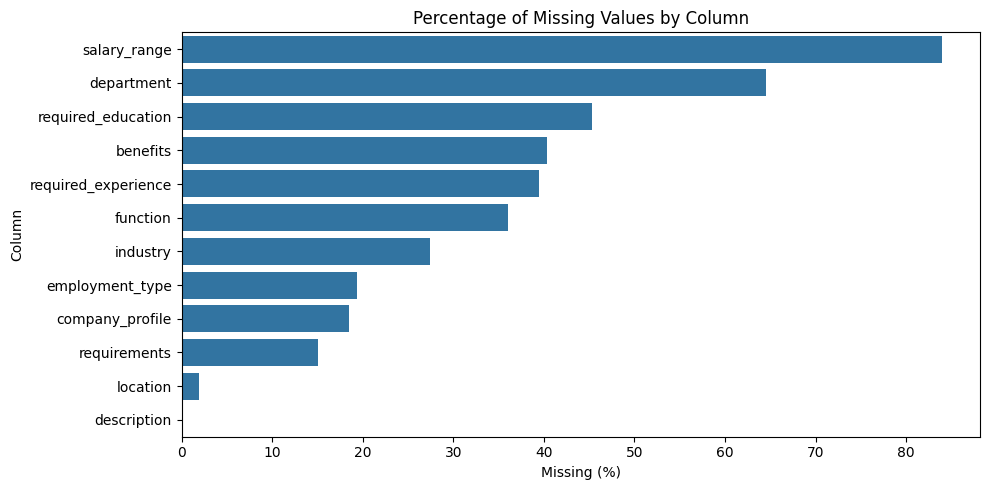

In [ ]:
# missing values and nulls check
# Count and percentage of missing values per column
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct
}).sort_values("missing_count", ascending=False)

print(f"Total missing cells: {missing.sum():,}")
print()
display(missing_df)

# bar chart of columns that have missing values for visual requirement
cols_with_missing = missing_df[missing_df["missing_count"] > 0]
if not cols_with_missing.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(x=cols_with_missing["missing_pct"], y=cols_with_missing.index)
    plt.xlabel("Missing (%)")
    plt.ylabel("Column")
    plt.title("Percentage of Missing Values by Column")
    plt.tight_layout()
    plt.show()

In [ ]:
# Count fully duplicated rows (all columns identical)
dup_count = df.duplicated().sum()
print(f"Duplicate rows: {dup_count:,} ({dup_count / len(df) * 100:.2f}%)")

# Look at the duplicates, if any
if dup_count > 0:
    display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))

Duplicate rows: 0 (0.00%)


In [ ]:
# Count blank strings (empty or whitespace-only) per text column BEFORE replacing
blank_counts = {}
for col in df.select_dtypes(include="object").columns:
    blank_counts[col] = df[col].astype(str).str.strip().eq("").sum()

blank_df = pd.Series(blank_counts, name="blank_strings")
print("Blank strings hiding as real values:")
display(blank_df[blank_df > 0].sort_values(ascending=False))

# Save the old null counts for comparison
before = df.isnull().sum()

Blank strings hiding as real values:


,blank_strings
benefits,8
department,6
requirements,2
description,1


In [ ]:
# Replace empty and whitespace-only strings with NaN
df = df.replace(r"^\s*$", np.nan, regex=True)

# Re-run the missing values summary
after = df.isnull().sum()
missing_df = pd.DataFrame({
    "missing_before": before,
    "missing_after": after,
    "newly_found": after - before,
    "missing_pct": (after / len(df) * 100).round(2)
}).sort_values("missing_after", ascending=False)

print(f"\nTotal missing cells: before = {before.sum():,}, after = {after.sum():,}")
display(missing_df)


Total missing cells: before = 70,106, after = 70,123


,missing_before,missing_after,newly_found,missing_pct
salary_range,15012,15012,0,83.96
department,11547,11553,6,64.61
required_education,8105,8105,0,45.33
benefits,7212,7220,8,40.38
required_experience,7050,7050,0,39.43
function,6455,6455,0,36.10
industry,4903,4903,0,27.42
employment_type,3471,3471,0,19.41
company_profile,3308,3308,0,18.50
requirements,2696,2698,2,15.09


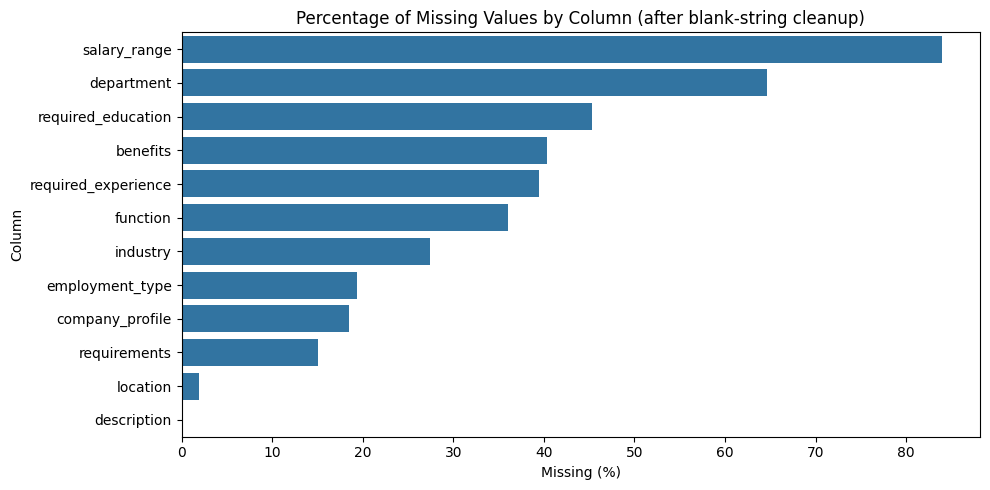

In [ ]:
# Bar chart of columns that have missing values
cols_with_missing = missing_df[missing_df["missing_after"] > 0]
if not cols_with_missing.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(x=cols_with_missing["missing_pct"], y=cols_with_missing.index)
    plt.xlabel("Missing (%)")
    plt.ylabel("Column")
    plt.title("Percentage of Missing Values by Column (after blank-string cleanup)")
    plt.tight_layout()
    plt.show()

**Research Question**

### Can the language of a job posting predict whether it is fraudulent, and which words drive that prediction?”

Methodolgy:


*   Class Balance
*   Clean and combine text
*   Train and Test Split
*   Features
*   Logistic Regression and eval
*   Top words for fraud vs real predictions




## Class Balancing

fraudulent
0    17014
1      866
Name: count, dtype: int64
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


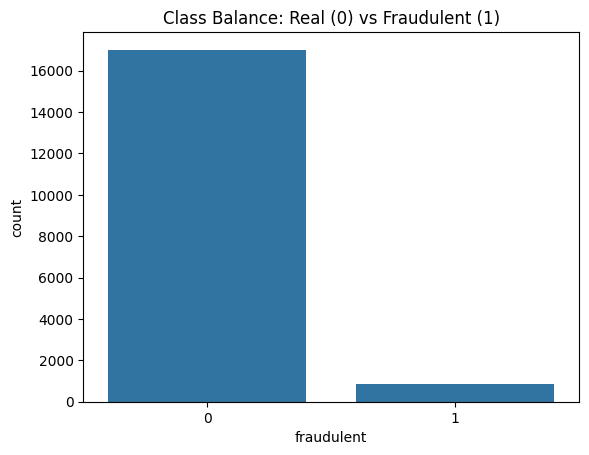

In [ ]:
print(df["fraudulent"].value_counts())
print((df["fraudulent"].value_counts(normalize=True) * 100).round(2))

sns.countplot(x="fraudulent", data=df)
plt.title("Class Balance: Real (0) vs Fraudulent (1)")
plt.show()

## Notes:
Class appears a bit imbalanced with a 20 to 1 for real for fake. Going to have to train on less "real posts and keep all the fakes to make a more balance training set.

Combine the text fields

In [ ]:
text_cols = ["title", "company_profile", "description", "requirements", "benefits"]

# Treat "Unknown" placeholders and NaN as empty text
df[text_cols] = df[text_cols].replace("Unknown", "").fillna("")

# One text field per posting
df["text"] = df[text_cols].agg(" ".join, axis=1)

df[["text", "fraudulent"]].head()

,text,fraudulent
0,"Marketing Intern We're Food52, and we've created a groun...",0
1,"Customer Service - Cloud Video Production 90 Seconds, th...",0
2,Commissioning Machinery Assistant (CMA) Valor Services p...,0
3,Account Executive - Washington DC Our passion for improv...,0
4,Bill Review Manager SpotSource Solutions LLC is a Global...,0


Clean the text

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("english"))

def clean_text(s):
    s = s.lower()
    s = re.sub(r"http\S+|www\.\S+", " ", s)   # URLs
    s = re.sub(r"<.*?>", " ", s)              # HTML tags
    s = re.sub(r"[^a-z\s]", " ", s)           # keep letters only
    tokens = [w for w in s.split() if w not in stop_words and len(w) > 2]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_text)
df[["clean_text", "fraudulent"]].head()

,clean_text,fraudulent
0,marketing intern food created groundbreaking award winni...,0
1,customer service cloud video production seconds worlds c...,0
2,commissioning machinery assistant cma valor services pro...,0
3,account executive washington passion improving quality l...,0
4,bill review manager spotsource solutions llc global huma...,0


In [ ]:
# checking to see if any posts have no words after cleaning
df["clean_len"] = df["clean_text"].str.split().str.len()

print("Empty clean_text rows:", (df["clean_len"] == 0).sum())
print(df.groupby("fraudulent")["clean_len"].median())

Empty clean_text rows: 0
fraudulent
0    233.0
1    156.5
Name: clean_len, dtype: float64


Test/Train Splitting

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["fraudulent"],
    test_size=0.2, random_state=42, stratify=df["fraudulent"]
)
print(X_train.shape, X_test.shape)

(14304,) (3576,)


checking stratification

In [ ]:
print("Train fraud rate:", round(y_train.mean() * 100, 2), "%")
print("Test fraud rate: ", round(y_test.mean() * 100, 2), "%")
print("Fraud cases in test:", y_test.sum())

Train fraud rate: 4.84 %
Test fraud rate:  4.84 %
Fraud cases in test: 173


term frequency and inverse doc frequency

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=5)
X_train_tfidf = tfidf.fit_transform(X_train)   # fit on train only
X_test_tfidf = tfidf.transform(X_test)

print(X_train_tfidf.shape)

(14304, 5000)


In [ ]:
features = tfidf.get_feature_names_out()
print(len(features))
print(features[:20])
print(features[2000:2020])

5000
['aabbf' 'abc' 'abc supply' 'abilities' 'ability' 'ability adapt'
 'ability build' 'ability communicate' 'ability effectively'
 'ability learn' 'ability manage' 'ability multi' 'ability prioritize'
 'ability take' 'ability work' 'able' 'able multi' 'able perform'
 'able work' 'abroad']
['hard work' 'hard working' 'hardware' 'hardware software' 'hardworking'
 'head' 'head office' 'headquartered' 'headquarters' 'health' 'health amp'
 'health care' 'health dental' 'health insurance' 'health safety'
 'healthcare' 'healthy' 'healthy spot' 'hear' 'hearing']


Model and Eval

              precision    recall  f1-score   support

        Real       0.99      0.97      0.98      3403
  Fraudulent       0.64      0.90      0.75       173

    accuracy                           0.97      3576
   macro avg       0.82      0.94      0.87      3576
weighted avg       0.98      0.97      0.97      3576

PR-AUC: 0.8874
(A random model would score about 0.0484)


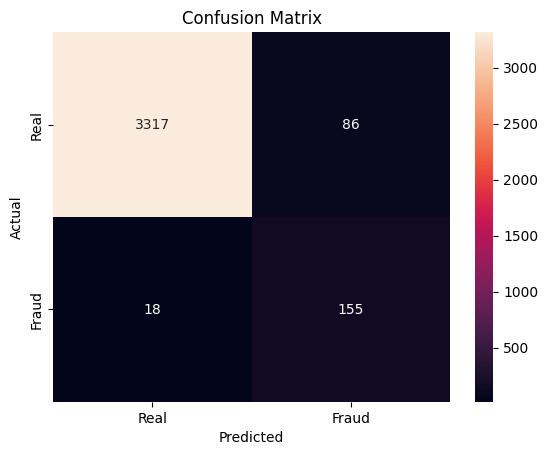

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

# train model
model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train_tfidf, y_train)

# predict and eval precision, f1, recall
y_pred = model.predict(X_test_tfidf)
print(classification_report(y_test, y_pred, target_names=["Real", "Fraudulent"]))

# eval
y_scores = model.predict_proba(X_test_tfidf)[:, 1]
print(f"PR-AUC: {average_precision_score(y_test, y_scores):.4f}")
print(f"(A random model would score about {y_test.mean():.4f})")

# confusion matrix heat map
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d",
            xticklabels=["Real", "Fraud"], yticklabels=["Real", "Fraud"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

Top Words Driving

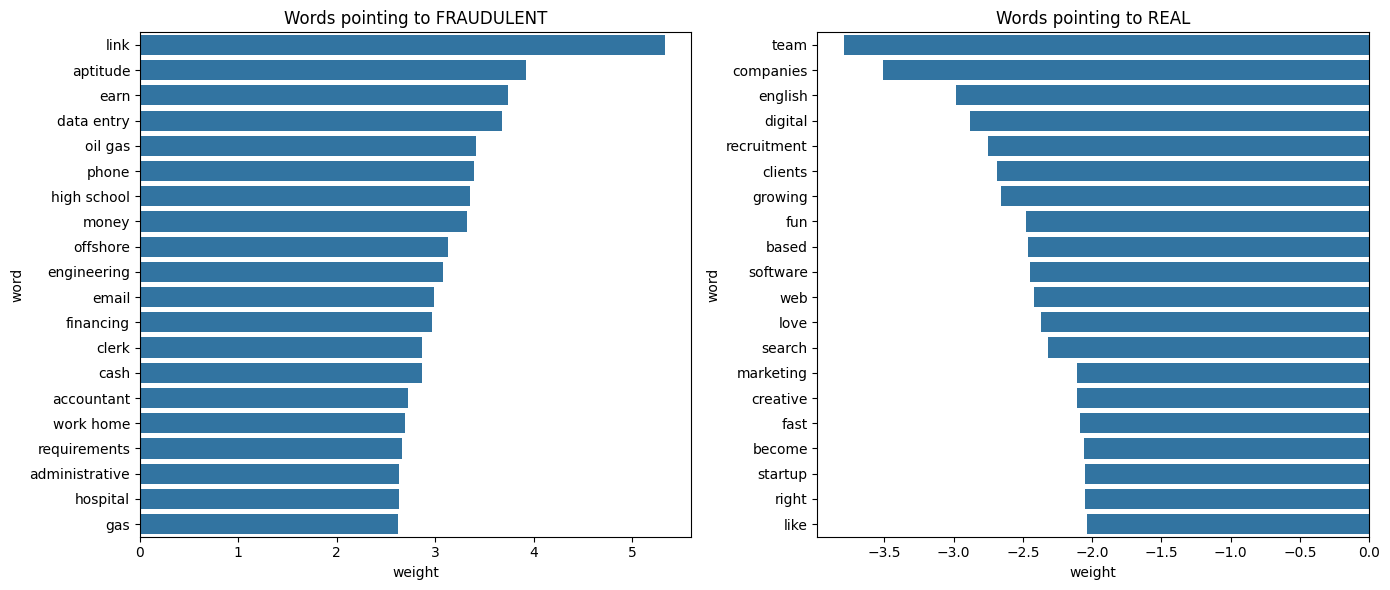

In [ ]:
# Get words for each column
feature_names = np.array(tfidf.get_feature_names_out())

# weights per word
coefs = model.coef_[0]

# 20 most fraud
top_fraud = pd.DataFrame({"word": feature_names[np.argsort(coefs)[-20:][::-1]],
                          "weight": np.sort(coefs)[-20:][::-1]})

# 20 most real
top_real = pd.DataFrame({"word": feature_names[np.argsort(coefs)[:20]],
                         "weight": np.sort(coefs)[:20]})

# side by side chart
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=top_fraud, x="weight", y="word", ax=axes[0]).set_title("Words pointing to FRAUDULENT")
sns.barplot(data=top_real, x="weight", y="word", ax=axes[1]).set_title("Words pointing to REAL")
plt.tight_layout()
plt.show()

Checking how many posting show/hold the top words

In [ ]:
rows = []
for w in top_fraud["word"]:
    mask = df["clean_text"].str.contains(r"\b" + re.escape(w) + r"\b", regex=True)
    rows.append({
        "word": w,
        "postings_with_word": mask.sum(),
        "fraud_rate_%": round(df.loc[mask, "fraudulent"].mean() * 100, 1)
    })

pd.DataFrame(rows).sort_values("postings_with_word", ascending=False)

,word,postings_with_word,fraud_rate_%
16,requirements,4295,5.7
9,engineering,3146,5.2
10,email,2756,8.3
5,phone,2344,7.7
17,administrative,961,13.3
6,high school,829,10.6
7,money,751,9.2
19,gas,486,18.3
13,cash,473,13.1
2,earn,424,34.4
